# 05 — DCGAN | Fashion-MNIST (Simple)

**Deep Convolutional GAN (DCGAN)** sesuai tugas komparasi: bandingkan dengan Vanilla GAN berbasis MLP. DCGAN menggunakan **ConvTranspose2d** pada Generator dan **Conv2d** pada Discriminator.

**Output untuk laporan PDF:** **FID-2048**, latency generasi **64 gambar**, training time/epoch, **Figur 2** (16 sampel baru), **Figur 4** (interpolasi latent), dan **Figur 5** (kurva loss G/D). MSE/PSNR/SSIM = **N/A** karena tidak ada encoder rekonstruksi.

**Konsistensi eksperimen:** Fashion-MNIST 70.000 gambar, split **80/10/10**, batch **128**, seed **42**, latent **64**, Adam **2×10⁻⁴**, **15 epoch** (baseline, bisa ditambah). Jalankan pada **working directory yang sama** dengan notebook sebelumnya agar `fashion_mnist_split_seed42.npz` dipakai ulang.

> GPU sangat disarankan. GAN bisa mengalami **mode collapse**; loss Generator/Discriminator yang kecil tidak otomatis berarti gambar lebih bagus. Nilai FID lebih kecil lebih baik.

## 1. Setup

In [1]:
# Jika belum terpasang, jalankan sekali di cell terpisah:
# %pip install -q torch torchvision numpy pandas matplotlib "torchmetrics[image]" torch-fidelity

from pathlib import Path
import random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import ConcatDataset, Subset, DataLoader
from torchvision import datasets, transforms

SEED, BATCH, LATENT, EPOCHS = 42, 128, 64, 15
LR, FID_SAMPLES = 2e-4, 2048
RESUME = False                  # ganti True jika ingin lanjut dari checkpoint
INVERSION_STEPS = 200          # untuk interpolasi antarkelas (GAN inversion)
OUT = Path('outputs/dcgan')
OUT.mkdir(parents=True, exist_ok=True)
SPLIT_FILE = Path('fashion_mnist_split_seed42.npz')
CHECKPOINT = OUT / 'dcgan_last.pt'

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
print('Device:', device)

Device: cuda


## 2. Dataset — pembagian sama dengan AE, VAE, dan Vanilla GAN

Data dinormalisasi ke **[0,1]**, sesuai dengan aktivasi `Sigmoid` pada output Generator. File split bersama penting agar test set identik.

In [2]:
full = ConcatDataset([
    datasets.FashionMNIST('data', train=True, download=True, transform=transforms.ToTensor()),
    datasets.FashionMNIST('data', train=False, download=True, transform=transforms.ToTensor()),
])
if SPLIT_FILE.exists():
    with np.load(SPLIT_FILE) as split:
        train_idx, val_idx, test_idx = split['train_idx'], split['val_idx'], split['test_idx']
else:
    idx = torch.randperm(len(full), generator=torch.Generator().manual_seed(SEED)).numpy()
    train_idx, val_idx, test_idx = idx[:56000], idx[56000:63000], idx[63000:]
    np.savez_compressed(SPLIT_FILE, train_idx=train_idx, val_idx=val_idx, test_idx=test_idx)

assert (len(train_idx), len(val_idx), len(test_idx)) == (56000, 7000, 7000)
assert len(np.unique(np.r_[train_idx, val_idx, test_idx])) == len(full)
train_set, val_set, test_set = [Subset(full, a.tolist()) for a in (train_idx, val_idx, test_idx)]
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_set, batch_size=BATCH, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH, shuffle=False)
print('Train / Val / Test:', len(train_set), len(val_set), len(test_set))

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 174kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.09MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.7MB/s]


Train / Val / Test: 56000 7000 7000


## 3. Arsitektur DCGAN (28×28 grayscale)

**Generator:** `z (64×1×1) → (256×7×7) → (128×14×14) → (1×28×28)`.

**Discriminator:** `gambar (1×28×28) → (64×14×14) → (128×7×7) → (1 logit)`.

Gunakan BatchNorm dan ReLU di Generator; LeakyReLU dan BatchNorm di Discriminator. Output D berupa **logit**, sehingga loss menggunakan `BCEWithLogitsLoss()` tanpa Sigmoid di akhir D.

In [3]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(LATENT, 256, 7, 1, 0), nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 1, 4, 2, 1), nn.Sigmoid()
        )
    def forward(self, z):
        return self.net(z)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 1, 7, 1, 0), nn.Flatten()
        )
    def forward(self, x):
        return self.net(x)

G, D = Generator().to(device), Discriminator().to(device)
opt_g = torch.optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(D.parameters(), lr=LR, betas=(0.5, 0.999))
loss_fn = nn.BCEWithLogitsLoss()
print('G params:', sum(p.numel() for p in G.parameters()))
print('D params:', sum(p.numel() for p in D.parameters()))
print('G output:', tuple(G(torch.randn(2, LATENT, 1, 1, device=device)).shape))
print('D output:', tuple(D(torch.randn(2, 1, 28, 28, device=device)).shape))

G params: 1330305
D params: 138817
G output: (2, 1, 28, 28)
D output: (2, 1)


## 4. Training dan validation

Untuk setiap batch: **(1)** D belajar membedakan real=1 / fake=0; **(2)** G belajar membuat fake yang dianggap real=1. Nilai loss D/G menggunakan formulasi *non-saturating GAN* seperti Vanilla GAN sebelumnya.

Simpan checkpoint **setiap epoch** (G, D, optimizer, history); ubah `RESUME=True` dan naikkan `EPOCHS` untuk melanjutkan. Validation BCE hanya indikator dinamika optimasi, **bukan** ukuran utama kualitas gambar.

In [4]:
def sync():
    if device.type == 'cuda': torch.cuda.synchronize()
    elif device.type == 'mps': torch.mps.synchronize()

def run_epoch(loader, training):
    G.train(training); D.train(training)
    total_d = total_g = total_n = 0
    with torch.set_grad_enabled(training):
        for real, _ in loader:
            real = real.to(device)
            n = len(real)
            ones, zeros = torch.ones(n, 1, device=device), torch.zeros(n, 1, device=device)
            z = torch.randn(n, LATENT, 1, 1, device=device)
            fake = G(z)

            if training: opt_d.zero_grad()
            d_loss = (loss_fn(D(real), ones) + loss_fn(D(fake.detach()), zeros)) / 2
            if training:
                d_loss.backward()
                opt_d.step()
                opt_g.zero_grad()
                for p in D.parameters(): p.requires_grad_(False)

            g_loss = loss_fn(D(fake), ones)
            if training:
                g_loss.backward()
                opt_g.step()
                for p in D.parameters(): p.requires_grad_(True)

            total_d += d_loss.item() * n
            total_g += g_loss.item() * n
            total_n += n
    return total_d / total_n, total_g / total_n

history, start_epoch = [], 1
if RESUME and CHECKPOINT.exists():
    saved = torch.load(CHECKPOINT, map_location=device, weights_only=False)  # checkpoint lokal sendiri
    G.load_state_dict(saved['G']); D.load_state_dict(saved['D'])
    opt_g.load_state_dict(saved['opt_g']); opt_d.load_state_dict(saved['opt_d'])
    history, start_epoch = saved['history'], saved['epoch'] + 1
    print('Melanjutkan dari epoch', start_epoch)

for epoch in range(start_epoch, EPOCHS + 1):
    sync(); t0 = time.perf_counter()
    train_d, train_g = run_epoch(train_loader, training=True)
    sync(); seconds = time.perf_counter() - t0
    val_d, val_g = run_epoch(val_loader, training=False)
    history.append(dict(epoch=epoch, train_d_loss=train_d, train_g_loss=train_g,
                        val_d_loss=val_d, val_g_loss=val_g, training_time_s=seconds))
    torch.save(dict(epoch=epoch, G=G.state_dict(), D=D.state_dict(),
                    opt_g=opt_g.state_dict(), opt_d=opt_d.state_dict(),
                    history=history), CHECKPOINT)
    print(f'Epoch {epoch:02d} | D={train_d:.4f}, G={train_g:.4f} |'
          f' Val D={val_d:.4f}, G={val_g:.4f} | {seconds:.1f}s')

if not history:
    raise RuntimeError('Belum ada training. Jalankan EPOCHS >= 1.')
history_df = pd.DataFrame(history)
history_df.to_csv(OUT / 'dcgan_history.csv', index=False)
G.eval(); D.eval()
torch.save(G.state_dict(), OUT / 'dcgan_generator.pt')

Epoch 01 | D=0.5307, G=1.1529 | Val D=0.6228, G=0.7643 | 19.8s
Epoch 02 | D=0.5790, G=0.9906 | Val D=0.6619, G=0.5895 | 18.9s
Epoch 03 | D=0.6123, G=0.9334 | Val D=0.6361, G=0.9115 | 18.9s
Epoch 04 | D=0.6232, G=0.9174 | Val D=0.6895, G=0.5091 | 18.8s
Epoch 05 | D=0.6239, G=0.9167 | Val D=0.6612, G=0.7089 | 18.5s
Epoch 06 | D=0.6211, G=0.9240 | Val D=0.6479, G=0.9013 | 18.4s
Epoch 07 | D=0.6205, G=0.9268 | Val D=0.6428, G=0.8035 | 18.7s
Epoch 08 | D=0.6173, G=0.9361 | Val D=0.6307, G=0.8711 | 18.4s
Epoch 09 | D=0.6163, G=0.9449 | Val D=0.6257, G=0.8665 | 18.5s
Epoch 10 | D=0.6119, G=0.9514 | Val D=0.6805, G=0.5901 | 18.3s
Epoch 11 | D=0.6117, G=0.9599 | Val D=0.6722, G=1.1853 | 18.4s
Epoch 12 | D=0.6085, G=0.9663 | Val D=0.6366, G=0.6696 | 18.5s
Epoch 13 | D=0.6068, G=0.9717 | Val D=0.6315, G=1.0541 | 18.3s
Epoch 14 | D=0.6043, G=0.9789 | Val D=0.7074, G=1.3258 | 18.6s
Epoch 15 | D=0.6018, G=0.9867 | Val D=0.6539, G=0.6029 | 18.4s


## 5. Inference latency — menghasilkan 64 gambar

Ukur **hanya forward pass Generator** untuk batch 64 dari latent yang sudah dibuat. Gunakan 10 warmup + 30 kali pengukuran seperti notebook Vanilla GAN.

In [5]:
z64 = torch.randn(64, LATENT, 1, 1, device=device)
with torch.inference_mode():
    for _ in range(10): G(z64)
    timings = []
    for _ in range(30):
        sync(); t0 = time.perf_counter()
        G(z64)
        sync(); timings.append((time.perf_counter() - t0) * 1000)
latency = float(np.mean(timings))
print(f'Latency: {latency:.3f} ± {np.std(timings):.3f} ms / batch 64')

Latency: 4.260 ± 0.860 ms / batch 64


## 6. Tiga visualisasi wajib DCGAN

- **Figur 2** — 16 sampel random dari distribusi Gaussian.
- **Figur 4** — interpolasi linear pada dua latent dari **kelas kontras** (T-shirt dan ankle boot). Karena model ini *unconditional*, pilih titik laten melalui **GAN inversion** (mencari dua `z` mendekati target gambar). Hasil inversi mungkin tidak identik dengan kelas target.
- **Figur 5** — training/validation loss G dan D.

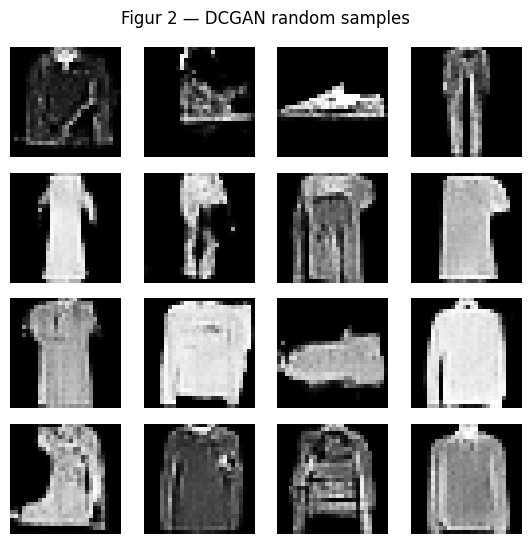

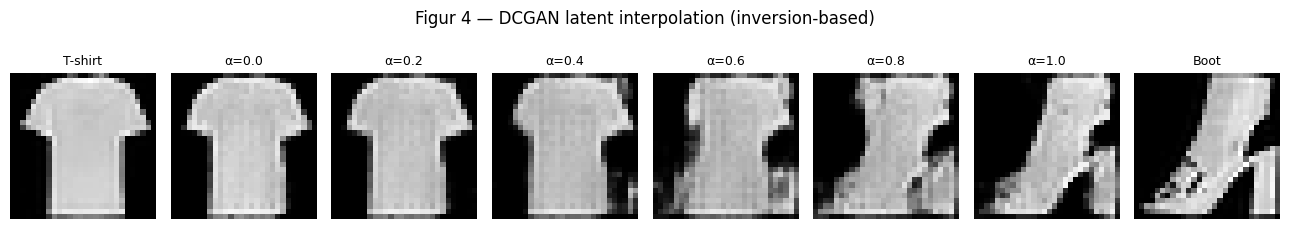

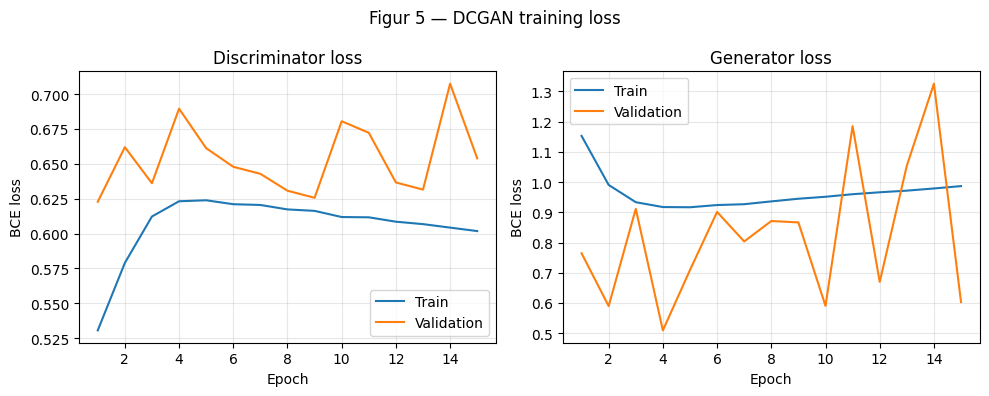

In [6]:
# Figur 2: sampel acak (4x4)
with torch.inference_mode():
    samples = G(torch.randn(16, LATENT, 1, 1, device=device)).cpu()
fig, axes = plt.subplots(4, 4, figsize=(5.5, 5.5))
for ax, img in zip(axes.flat, samples):
    ax.imshow(img[0], cmap='gray', vmin=0, vmax=1); ax.axis('off')
fig.suptitle('Figur 2 — DCGAN random samples')
plt.tight_layout(); plt.savefig(OUT / 'figure2_dcgan_samples.png', dpi=200); plt.show()

# Figur 4: GAN inversion dua kelas (0 = T-shirt, 9 = ankle boot)
def class_image(label):
    for img, y in test_set:
        if y == label: return img
    raise ValueError('Kelas tidak ditemukan')

targets = torch.stack([class_image(0), class_image(9)]).to(device)
G.eval()
for p in G.parameters(): p.requires_grad_(False)
z_pair = nn.Parameter(torch.randn(2, LATENT, 1, 1, device=device))
z_opt = torch.optim.Adam([z_pair], lr=0.05)
for _ in range(INVERSION_STEPS):
    z_opt.zero_grad()
    inversion_loss = F.mse_loss(G(z_pair), targets) + 0.001 * z_pair.square().mean()
    inversion_loss.backward()
    z_opt.step()

alphas = np.linspace(0.0, 1.0, 6)
with torch.inference_mode():
    a, b = z_pair.detach()[0], z_pair.detach()[1]
    interpolated = G(torch.stack([(1-float(t))*a + float(t)*b for t in alphas])).cpu()
for p in G.parameters(): p.requires_grad_(True)

fig, axes = plt.subplots(1, 8, figsize=(13, 2.5))
for i, ax in enumerate(axes):
    img = targets[0, 0].cpu() if i == 0 else targets[1, 0].cpu() if i == 7 else interpolated[i-1, 0]
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.set_title('T-shirt' if i == 0 else 'Boot' if i == 7 else f'α={alphas[i-1]:.1f}', fontsize=9)
    ax.axis('off')
fig.suptitle('Figur 4 — DCGAN latent interpolation (inversion-based)')
plt.tight_layout(); plt.savefig(OUT / 'figure4_dcgan_interpolation.png', dpi=200); plt.show()

# Figur 5: training loss curves
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, key in zip(axes, ['d', 'g']):
    ax.plot(history_df.epoch, history_df[f'train_{key}_loss'], label='Train')
    ax.plot(history_df.epoch, history_df[f'val_{key}_loss'], label='Validation')
    ax.set(xlabel='Epoch', ylabel='BCE loss', title=f'{"Discriminator" if key == "d" else "Generator"} loss')
    ax.legend(); ax.grid(alpha=0.3)
fig.suptitle('Figur 5 — DCGAN training loss')
plt.tight_layout(); plt.savefig(OUT / 'figure5_dcgan_loss.png', dpi=200); plt.show()

## 7. FID (Inception-2048) — test set vs gambar generated

Sama seperti VAE dan Vanilla GAN: gunakan **2048 gambar nyata dari test set** dan **2048 hasil generasi acak**, lalu hitung Fréchet Inception Distance pada fitur **Inception 2048**. Grayscale disalin menjadi 3 kanal untuk Inception. Di Mac MPS, FID dihitung pada CPU.

> Jika dependensi belum tersedia: `%pip install -q "torchmetrics[image]" torch-fidelity`. Unduhan bobot Inception mungkin membutuhkan internet. **Jangan melaporkan FID palsu** jika cell ini belum berhasil dijalankan.

In [9]:
%pip install -q "torchmetrics[image]" torch-fidelity

In [10]:
from torchmetrics.image.fid import FrechetInceptionDistance

fid_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
metric = FrechetInceptionDistance(feature=2048, normalize=True).to(fid_device)
metric.set_dtype(torch.float64)
fid_rng = torch.Generator().manual_seed(SEED + 123)

seen = 0
with torch.inference_mode():
    G.eval()
    for real, _ in test_loader:
        if seen >= FID_SAMPLES: break
        real = real[:FID_SAMPLES - seen]
        z = torch.randn(len(real), LATENT, 1, 1, generator=fid_rng).to(device)
        fake = G(z).to(fid_device)
        metric.update(real.to(fid_device).repeat(1, 3, 1, 1), real=True)
        metric.update(fake.repeat(1, 3, 1, 1), real=False)
        seen += len(real)
        if seen % 512 == 0: print('FID progress:', seen, '/', FID_SAMPLES)

fid_score = float(metric.compute().item())
print(f'FID-2048 ({seen} real + {seen} generated): {fid_score:.3f}')

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 175MB/s]


FID progress: 512 / 2048
FID progress: 1024 / 2048
FID progress: 1536 / 2048
FID progress: 2048 / 2048
FID-2048 (2048 real + 2048 generated): 38.013


## 8. Ekspor hasil untuk final comparison

Hasil `.csv`, `.pt`, `.png` disimpan di `outputs/dcgan/`. Otomatis membuat komparasi ringkas dengan Vanilla GAN apabila file metriks sebelumnya tersedia.

In [11]:
result = pd.DataFrame([{
    'model': 'DCGAN', 'dataset': 'Fashion-MNIST', 'seed': SEED,
    'train_size': len(train_set), 'val_size': len(val_set), 'test_size': len(test_set),
    'latent_dim': LATENT, 'batch_size': BATCH, 'epochs': int(history_df.epoch.iloc[-1]),
    'num_parameters': sum(p.numel() for p in G.parameters()) + sum(p.numel() for p in D.parameters()),
    'learning_rate': LR,
    'training_time_epoch_s_mean': float(history_df.training_time_s.mean()),
    'inference_latency_batch64_ms': latency,
    'test_mse': float('nan'), 'test_psnr_db': float('nan'), 'test_ssim': float('nan'),
    'fid': fid_score, 'fid_features': 2048, 'fid_samples': seen,
    'final_d_loss': float(history_df.train_d_loss.iloc[-1]),
    'final_g_loss': float(history_df.train_g_loss.iloc[-1]),
    'device': str(device)
}])
result.to_csv(OUT / 'dcgan_metrics.csv', index=False)
print(result.T.to_string(header=False))

previous = Path('outputs/vanilla_gan/vanilla_gan_metrics.csv')
if previous.exists():
    columns = ['model', 'fid', 'inference_latency_batch64_ms', 'training_time_epoch_s_mean']
    comparison = pd.concat([pd.read_csv(previous), result], ignore_index=True)
    comparison[columns].to_csv(OUT / 'vanilla_gan_vs_dcgan.csv', index=False)
    print('\nVanilla GAN vs DCGAN:')
    print(comparison[columns].to_string(index=False))
print('Hasil tersimpan:', OUT.resolve())

model                                 DCGAN
dataset                       Fashion-MNIST
seed                                     42
train_size                            56000
val_size                               7000
test_size                              7000
latent_dim                               64
batch_size                              128
epochs                                   15
num_parameters                      1469122
learning_rate                        0.0002
training_time_epoch_s_mean        18.625166
inference_latency_batch64_ms       4.260332
test_mse                                NaN
test_psnr_db                            NaN
test_ssim                               NaN
fid                               38.013328
fid_features                           2048
fid_samples                            2048
final_d_loss                       0.601813
final_g_loss                       0.986692
device                                 cuda
Hasil tersimpan: /content/output

In [12]:
from google.colab import drive
drive.mount('/content/drive')
!cp -r "/content/outputs/dcgan" "/content/drive/MyDrive/[CN] Colab Notebooks/[CV] Computer Vision/DCGANAE: All Experiments/Results"


Mounted at /content/drive


### File yang dihasilkan

- `outputs/dcgan/dcgan_last.pt`: checkpoint G+D+optimizer **setiap epoch** (bisa resume).
- `outputs/dcgan/dcgan_generator.pt`: bobot Generator akhir.
- `outputs/dcgan/dcgan_history.csv`: kurva loss dan waktu/epoch.
- `outputs/dcgan/dcgan_metrics.csv`: FID, latency, train time, dan N/A untuk MSE/PSNR/SSIM.
- `outputs/dcgan/figure2_dcgan_samples.png`: 16 sampel generatif.
- `outputs/dcgan/figure4_dcgan_interpolation.png`: interpolasi 6 langkah dan dua target.
- `outputs/dcgan/figure5_dcgan_loss.png`: kurva G/D.
- `outputs/dcgan/vanilla_gan_vs_dcgan.csv`: opsional, jika file hasil Vanilla GAN ada.

**Pembahasan untuk Q3:** jelaskan perbedaan G/D loss, kualitas gambar, risiko mode collapse, serta FID dan latency DCGAN vs Vanilla GAN. Untuk Q4 gunakan Figur 4. Arsitektur convolutional mempertahankan inductive bias spasial yang tidak dimiliki MLP.